In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv('../Data Science/datasets/mall_customers.csv')
display(data.head())

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
data.rename({'Annual Income (k$)': 'Income', 'Spending Score (1-100)' : 'Spending Score'}, axis = 1, inplace= True)
display(data.head())

,CustomerID,Gender,Age,Income,Spending Score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


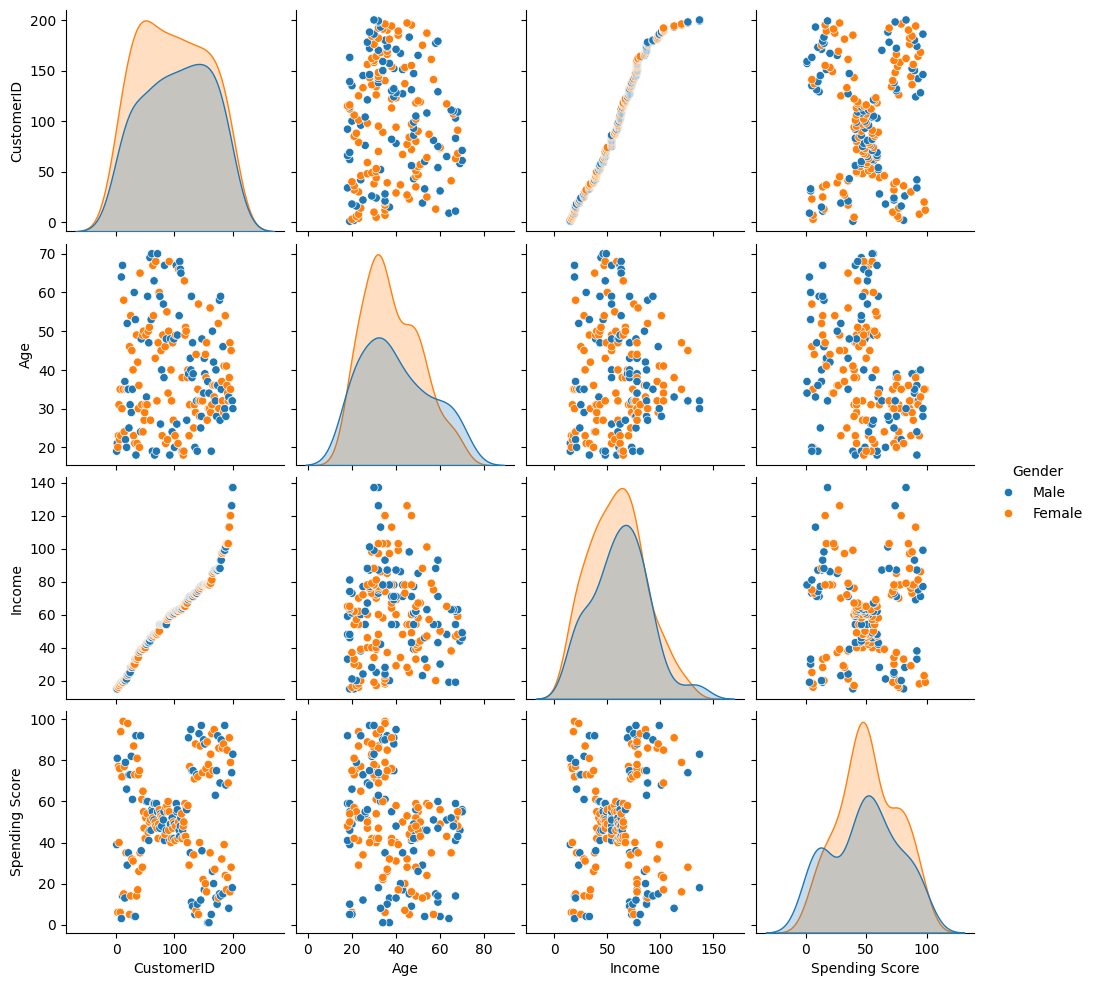

In [4]:
sns.pairplot(data, hue = 'Gender')

In [5]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler


In [6]:
X = data[['Income', 'Spending Score']]
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [7]:
kmeans = KMeans(n_clusters= 5, n_init= 10, random_state= 0)
kmeans.fit(X_scaled)

labels= kmeans.labels_
centroids = kmeans.cluster_centers_

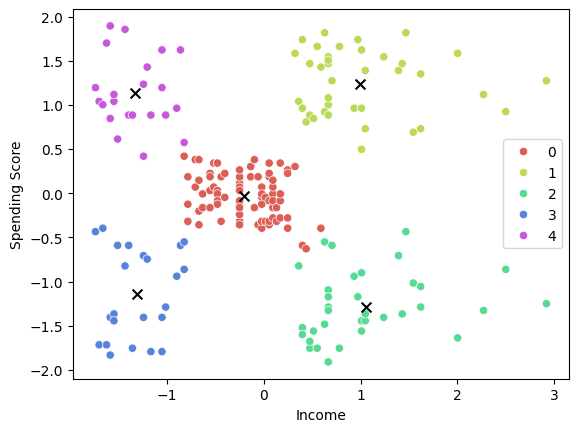

In [8]:
sns.scatterplot(x = X_scaled[:, 0], y = X_scaled[:,1], hue = labels, legend = 'full', palette= sns.color_palette('hls', 5))
plt.xlabel('Income')
plt.ylabel('Spending Score')
plt.scatter(centroids[:,0], centroids[:,1], marker = 'x', s = 50, color = 'k')

Text(0.5, 0, 'Núm de clusters')

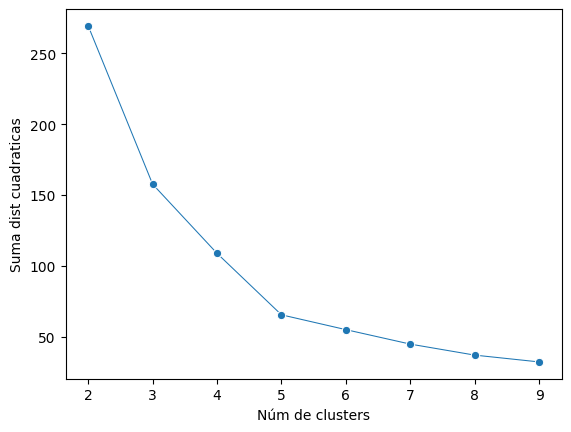

In [9]:
sq_distances = []
k_values = range(2,10)

for k in k_values:
    kmeans = KMeans(n_clusters= k, n_init= 10, random_state= 0)
    kmeans.fit(X_scaled)
    sq_distances.append(kmeans.inertia_)

sns.lineplot(x = k_values, y = sq_distances, marker = 'o', size= 30, legend= False)
plt.ylabel('Suma dist cuadraticas')
plt.xlabel('Núm de clusters')

Text(0.5, 0, 'Núm de clusters')

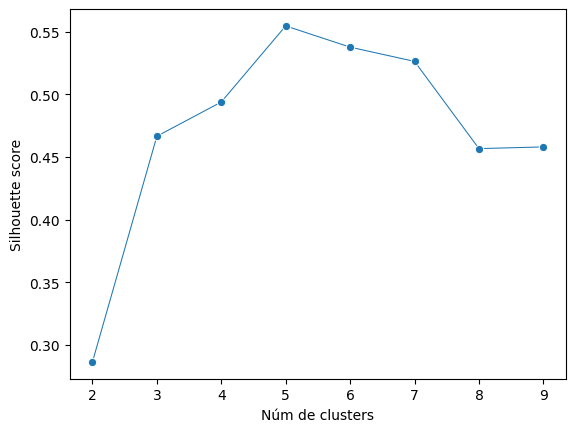

In [10]:
from sklearn.metrics import silhouette_score, silhouette_samples

sil = []
k_values = range(2,10)

for k in k_values:
    kmeans = KMeans(n_clusters= k, n_init= 10, random_state=0)
    kmeans.fit(X_scaled)
    score = silhouette_score(X_scaled, kmeans.labels_)
    sil.append(score)

sns.lineplot( x = k_values, y = sil, marker = 'o', size = 30, legend= False)
plt.ylabel('Silhouette score')
plt.xlabel('Núm de clusters')
